<a href="https://colab.research.google.com/github/LiliiaKuchvara/ecommerce-sales-analysis-2025-/blob/main/07_%D0%A4%D1%96%D0%BD%D0%B0%D0%BB%D1%8C%D0%BD%D0%B8%D0%B9_%D0%BF%D1%80%D0%BE%D1%94%D0%BA%D1%82_02_11_2026.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 🐼📈 Pandas і графіки для аналітиків · Блокнот 7 з 7
## Фінальний проєкт · 📈 Дашборд для керівника

### 🎯 Ваше завдання
Ви — аналітик інтернет-магазину. Керівник пише:

> «Привіт! Підготуй, будь ласка, підсумки 2025 року: скільки заробили, як ішли продажі по місяцях, які товари й міста найкращі, хто наші клієнти і де проблеми. Зроби одну картинку-дашборд і скинь усе в Excel, щоб я міг показати на нараді.»

У вас три файли: **`orders.csv`**, **`customers.csv`**, **`products.csv`**. Як і в більшості реальних компаній, дані в них **англійською**.

### Як працювати
- Проєкт складається з **11 кроків**. У тілі блокнота — **лише завдання**, щоб ви могли спробувати все зробити самостійно.
- 💡 **Підказки** до кожного кроку зібрано **в кінці блокнота**, у розділі «Підказки».
- ✅ Ще нижче — **розв'язки** (сховані, натисніть «Показати код»).
- ⚠️ Використовуйте **назви змінних із завдань** (`data`, `delivered`, `monthly` …): наступні кроки на них спираються. Якщо застрягли на якомусь кроці, запустіть його розв'язок у кінці блокнота: він створить потрібні змінні, і можна повертатися до наступного кроку.


## 📖 Опис даних

**`orders.csv`** — замовлення (3000 рядків)

| Стовпець | Що означає | Значення |
|---|---|---|
| `order_id` | номер замовлення | 100001 … 103000 |
| `order_date` | дата замовлення | 2025-01-01 … 2025-12-31 |
| `delivery_date` | дата доставки | порожньо, якщо замовлення скасували |
| `customer_id` | код клієнта | C0001 … C0400 |
| `product_id` | код товару | P01 … P18 |
| `quantity` | кількість одиниць | 1–4 |
| `payment` | спосіб оплати | `Card` — картка, `Cash on delivery` — накладений платіж, `Google/Apple Pay` |
| `channel` | канал продажів | `Website` — сайт, `App` — мобільний додаток, `Instagram` |
| `status` | статус замовлення | `Delivered` — доставлено, `Cancelled` — скасовано, `Returned` — повернено |
| `rating` | оцінка клієнта, 1–5 | порожньо, якщо клієнт не оцінив |

**`customers.csv`** — клієнти (400 рядків)

| Стовпець | Що означає | Значення |
|---|---|---|
| `customer_id` | код клієнта | C0001 … C0400 |
| `name` | ім'я | Olena, Andrii, … |
| `city` | місто | `Kyiv`, `Lviv`, `Odesa`, `Kharkiv`, `Dnipro` |
| `age` | вік | 18–65 |
| `registration_date` | дата реєстрації | 2022–2024 |

**`products.csv`** — товари (18 рядків)

| Стовпець | Що означає | Значення |
|---|---|---|
| `product_id` | код товару | P01 … P18 |
| `product` | назва | Headphones, Smartwatch, T-shirt, Mug, … |
| `category` | категорія | `Electronics` — електроніка, `Clothing` — одяг, `Home` — дім, `Beauty` — краса, `Sports` — спорт |
| `price` | ціна за одиницю, грн | 180–4200 |
| `cost` | собівартість одиниці, грн | 60–2900 |

⚠️ Текстові значення в умовах треба писати **точно так, як у даних**, з тим самим регістром: `"Delivered"`, а не `"delivered"`.

## Крок 0. Дані та бібліотеки

In [ ]:
# @title 📦 Підготовка даних — просто запустіть цю клітинку (Shift + Enter)
# Ця клітинка створює три файли з даними інтернет-магазину за 2025 рік (дані англійською).
# Розбиратися в її коді не потрібно.
# Якщо Colab перезапустився і файли зникли — просто запустіть її ще раз.

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

rng = np.random.default_rng(2025)

# ---------- Товари ----------
products = pd.DataFrame([
    ("P01", "Headphones",        "Electronics", 1500,  900),
    ("P02", "Power bank",        "Electronics",  900,  520),
    ("P03", "Smartwatch",        "Electronics", 4200, 2900),
    ("P04", "Bluetooth speaker", "Electronics", 2100, 1300),
    ("P05", "T-shirt",           "Clothing",       450,  180),
    ("P06", "Hoodie",            "Clothing",      1200,  550),
    ("P07", "Jeans",             "Clothing",      1600,  800),
    ("P08", "Sneakers",          "Clothing",      2800, 1600),
    ("P09", "Mug",               "Home",          180,   60),
    ("P10", "Blanket",           "Home",          850,  400),
    ("P11", "Desk lamp",         "Home",         1100,  600),
    ("P12", "Towel set",         "Home",          650,  300),
    ("P13", "Face cream",        "Beauty",       520,  210),
    ("P14", "Shampoo",           "Beauty",       260,  110),
    ("P15", "Perfume",           "Beauty",      2400, 1300),
    ("P16", "Yoga mat",          "Sports",       700,  320),
    ("P17", "Water bottle",      "Sports",       350,  140),
    ("P18", "Dumbbells 5 kg",    "Sports",       950,  550),
], columns=["product_id", "product", "category", "price", "cost"])

# ---------- Клієнти ----------
n_cust = 400
names = ["Olena", "Andrii", "Mariia", "Ihor", "Nataliia", "Dmytro", "Iryna", "Oleksandr",
         "Tetiana", "Serhii", "Yuliia", "Maksym", "Oksana", "Viktor", "Anna", "Bohdan",
         "Kateryna", "Taras", "Sofiia", "Roman"]
cities = ["Kyiv", "Lviv", "Odesa", "Kharkiv", "Dnipro"]
reg = pd.Timestamp("2022-01-01") + pd.to_timedelta(rng.integers(0, 3 * 365, n_cust), unit="D")
customers = pd.DataFrame({
    "customer_id": [f"C{i:04d}" for i in range(1, n_cust + 1)],
    "name": rng.choice(names, n_cust),
    "city": rng.choice(cities, n_cust, p=[0.35, 0.2, 0.15, 0.15, 0.15]),
    "age": np.clip(rng.normal(33, 9, n_cust).round(), 18, 65).astype(int),
    "registration_date": reg.strftime("%Y-%m-%d"),
})

# ---------- Замовлення ----------
n = 3000
days = pd.date_range("2025-01-01", "2025-12-31")
w = np.linspace(0.85, 1.15, len(days))          # магазин поступово росте
w[days.month.isin([6, 7, 8])] *= 0.8            # влітку спокійніше
w[days.month.isin([11, 12])] *= 1.5             # сезон розпродажів і свят
w[days.dayofweek >= 5] *= 1.3                   # у вихідні купують більше
w[days == pd.Timestamp("2025-11-28")] *= 6      # Чорна п'ятниця
order_date = pd.DatetimeIndex(np.sort(rng.choice(days.values, n, p=w / w.sum())))

cust_w = rng.gamma(1.0, 1, n_cust)
cust_idx = rng.choice(n_cust, n, p=cust_w / cust_w.sum())
prod_w = 1 / np.sqrt(products["price"].to_numpy())
prod_idx = rng.choice(len(products), n, p=prod_w / prod_w.sum())

quantity = rng.choice([1, 2, 3, 4], n, p=[0.72, 0.18, 0.07, 0.03])
payment = rng.choice(["Card", "Cash on delivery", "Google/Apple Pay"], n, p=[0.55, 0.27, 0.18])
channel = rng.choice(["Website", "App", "Instagram"], n, p=[0.5, 0.35, 0.15])

cod = payment == "Cash on delivery"
u = rng.random(n)
status = np.where(u < np.where(cod, 0.80, 0.91), "Delivered",
                  np.where(u < np.where(cod, 0.92, 0.96), "Cancelled", "Returned"))

city = customers["city"].to_numpy()[cust_idx]
deliv_days = np.where(city == "Kyiv", rng.integers(1, 3, n), rng.integers(1, 6, n))
delivery = order_date + pd.to_timedelta(deliv_days, unit="D")
delivery_str = np.where(status == "Cancelled", None, delivery.strftime("%Y-%m-%d"))

rating = np.where(deliv_days >= 4,
                  rng.choice(5, n, p=[0.08, 0.12, 0.22, 0.33, 0.25]) + 1,
                  rng.choice(5, n, p=[0.03, 0.05, 0.12, 0.35, 0.45]) + 1).astype(float)
returned = status == "Returned"
rating[returned] = rng.choice([1, 2, 3], returned.sum(), p=[0.5, 0.3, 0.2])
rating[(status == "Cancelled") | (rng.random(n) > 0.6)] = np.nan

orders = pd.DataFrame({
    "order_id": np.arange(100001, 100001 + n),
    "order_date": order_date.strftime("%Y-%m-%d"),
    "delivery_date": delivery_str,
    "customer_id": customers["customer_id"].to_numpy()[cust_idx],
    "product_id": products["product_id"].to_numpy()[prod_idx],
    "quantity": quantity,
    "payment": payment,
    "channel": channel,
    "status": status,
    "rating": rating,
})

# ---------- Зберігаємо файли ----------
orders.to_csv("orders.csv", index=False)
customers.to_csv("customers.csv", index=False)
products.to_csv("products.csv", index=False)

# ---------- Налаштування вигляду таблиць і стиль графіків ----------
pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", lambda x: f"{x:,.2f}".replace(",", " "))
plt.rcParams.update({
    "figure.figsize": (8, 4),
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "axes.axisbelow": True,
    "grid.alpha": 0.3,
    "lines.linewidth": 2,
    "legend.frameon": False,
    "axes.prop_cycle": plt.cycler(color=["#2a78d6", "#eb6834", "#1baf7a", "#eda100",
                                         "#e87ba4", "#008300", "#6250d6", "#e34948"]),
})

del (rng, names, cities, reg, n, n_cust, days, w, order_date, cust_w, cust_idx, prod_w, prod_idx,
     quantity, payment, channel, cod, u, status, city, deliv_days, delivery, delivery_str, rating,
     returned, orders, customers, products)

print("✅ Готово! Створено файли: orders.csv, customers.csv, products.csv")

✅ Готово! Створено файли: orders.csv, customers.csv, products.csv


In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

---
## Крок 1. Завантаження і перевірка даних

**Завдання:**
1. Прочитайте три файли у змінні `orders`, `customers`, `products`.
2. Для кожної таблиці подивіться розмір, перші рядки та пропуски.
3. Перевірте, що ключі унікальні: `order_id` у замовленнях, `customer_id` у клієнтах, `product_id` у товарах.
4. Поясніть собі: чому в деяких стовпцях є пропуски? Це помилка в даних чи ні?

In [ ]:
# Завантаження трьох файлів
orders = pd.read_csv("orders.csv")
customers = pd.read_csv("customers.csv")
products = pd.read_csv("products.csv")

In [ ]:
# Завантаження трьох файлів
print("Orders:", orders.shape)
print("Customers:", customers.shape)
print("Products:", products.shape)

Orders: (3000, 10)
Customers: (400, 5)
Products: (18, 5)


In [ ]:
# Перегляд перших рядків
display(orders.head())
display(customers.head())
display(products.head())

,order_id,order_date,delivery_date,customer_id,product_id,quantity,payment,channel,status,rating
0,100001,2025-01-01,NaN,C0230,P18,4,Card,Website,Cancelled,NaN
1,100002,2025-01-01,2025-01-02,C0074,P03,3,Google/Apple Pay,Website,Delivered,5.00
2,100003,2025-01-01,2025-01-05,C0216,P03,1,Google/Apple Pay,Website,Delivered,NaN
3,100004,2025-01-01,2025-01-02,C0219,P04,1,Cash on delivery,Instagram,Delivered,5.00
4,100005,2025-01-01,2025-01-06,C0026,P11,1,Card,App,Delivered,4.00


,customer_id,name,city,age,registration_date
0,C0001,Sofiia,Lviv,29,2023-05-05
1,C0002,Tetiana,Dnipro,27,2024-12-24
2,C0003,Andrii,Kharkiv,35,2024-12-22
3,C0004,Iryna,Dnipro,29,2023-02-23
4,C0005,Sofiia,Odesa,40,2024-11-10


,product_id,product,category,price,cost
0,P01,Headphones,Electronics,1500,900
1,P02,Power bank,Electronics,900,520
2,P03,Smartwatch,Electronics,4200,2900
3,P04,Bluetooth speaker,Electronics,2100,1300
4,P05,T-shirt,Clothing,450,180


In [ ]:
# Перевірка пропущених значень
print("Orders:")
display(orders.isna().sum())

print("Customers:")
display(customers.isna().sum())

print("Products:")
display(products.isna().sum())

Orders:


,0
order_id,0
order_date,0
delivery_date,205
customer_id,0
product_id,0
quantity,0
payment,0
channel,0
status,0
rating,1255


Customers:


,0
customer_id,0
name,0
city,0
age,0
registration_date,0


Products:


,0
product_id,0
product,0
category,0
price,0
cost,0


In [ ]:
# Перевірка унікальності ключів
print("Orders:", orders["order_id"].is_unique)
print("Customers:", customers["customer_id"].is_unique)
print("Products:", products["product_id"].is_unique)

Orders: True
Customers: True
Products: True


In [ ]:
# Відповідність статусу замовлення та дати доставки
print(
    orders.groupby("status")["delivery_date"]
    .apply(lambda x: x.isna().sum())
)

status
Cancelled    205
Delivered      0
Returned       0
Name: delivery_date, dtype: int64


---
## Крок 2. Підготовка: одна велика таблиця

**Завдання:**
1. Перетворіть `order_date` і `delivery_date` у `orders` на дати.
2. Об'єднайте `orders` з `products` і `customers` у таблицю **`data`**. Переконайтеся, що рядків стільки ж, скільки замовлень.
3. Додайте в `data` стовпці:
   - `revenue` — ціна × кількість;
   - `profit` — (ціна − собівартість) × кількість;
   - `month` — місяць замовлення;
   - `delivery_days` — скільки днів ішла доставка.
4. Створіть таблицю **`delivered`**: лише замовлення зі статусом `Delivered`. Саме вони принесли магазину гроші.

In [ ]:
# 1. Перетворення дат
orders["order_date"] = pd.to_datetime(orders["order_date"])
orders["delivery_date"] = pd.to_datetime(orders["delivery_date"])

# 2. Об'єднання таблиць
data = orders.merge(products, on="product_id", how="left")
data = data.merge(customers, on="customer_id", how="left")

# 3. Перевірка кількості рядків
print("Orders:", len(orders))
print("Data:", len(data))

# 4. Фінансові показники
data["revenue"] = data["price"] * data["quantity"]
data["profit"] = (data["price"] - data["cost"]) * data["quantity"]

# 5. Місяць замовлення
data["month"] = data["order_date"].dt.month

# 6. Тривалість доставки
data["delivery_days"] = (
    data["delivery_date"] - data["order_date"]
).dt.days

# 7. Лише доставлені замовлення
delivered = data[data["status"] == "Delivered"].copy()

# 8. Перевірка
print("Delivered orders:", len(delivered))
display(data.head())

Orders: 3000
Data: 3000
Delivered orders: 2664


,order_id,order_date,delivery_date,customer_id,product_id,quantity,payment,channel,status,rating,product,category,price,cost,name,city,age,registration_date,revenue,profit,month,delivery_days
0,100001,2025-01-01,NaT,C0230,P18,4,Card,Website,Cancelled,NaN,Dumbbells 5 kg,Sports,950,550,Sofiia,Kyiv,29,2023-01-28,3800,1600,1,NaN
1,100002,2025-01-01,2025-01-02,C0074,P03,3,Google/Apple Pay,Website,Delivered,5.00,Smartwatch,Electronics,4200,2900,Oksana,Odesa,33,2023-09-21,12600,3900,1,1.00
2,100003,2025-01-01,2025-01-05,C0216,P03,1,Google/Apple Pay,Website,Delivered,NaN,Smartwatch,Electronics,4200,2900,Kateryna,Odesa,43,2023-12-09,4200,1300,1,4.00
3,100004,2025-01-01,2025-01-02,C0219,P04,1,Cash on delivery,Instagram,Delivered,5.00,Bluetooth speaker,Electronics,2100,1300,Yuliia,Kyiv,23,2023-12-30,2100,800,1,1.00
4,100005,2025-01-01,2025-01-06,C0026,P11,1,Card,App,Delivered,4.00,Desk lamp,Home,1100,600,Mariia,Lviv,34,2022-07-02,1100,500,1,5.00


---
## Крок 3. Ключові показники (KPI) року

**Завдання:**
Зберіть у змінну **`kpi`** (Series з назвами показників):
- виручка і прибуток (по доставлених замовленнях);
- кількість доставлених замовлень;
- середній чек (середня виручка доставленого замовлення);
- кількість покупців (унікальні клієнти серед доставлених);
- частка скасованих і частка повернених замовлень, % (від **усіх** замовлень);
- середня оцінка.

In [ ]:
kpi = pd.Series({
    "Revenue": delivered["revenue"].sum(),

    "Profit": delivered["profit"].sum(),

    "Orders": len(delivered),

    "Average Check": delivered["revenue"].mean(),

    "Customers": delivered["customer_id"].nunique(),

    "Cancelled %": (data["status"] == "Cancelled").mean() * 100,

    "Returned %": (data["status"] == "Returned").mean() * 100,

    "Average Rating": data["rating"].mean()
})

display(kpi)

,0
Revenue,3 524 820.00
Profit,1 626 700.00
Orders,2 664.00
Average Check,1 323.13
Customers,353.00
Cancelled %,6.83
Returned %,4.37
Average Rating,3.90


In [ ]:
# Перевірка правильності розрахунків
print("Перевірка Revenue:",
      kpi["Revenue"] == delivered["revenue"].sum())

print("Перевірка Profit:",
      kpi["Profit"] == delivered["profit"].sum())

print("Перевірка Average Check:",
      np.isclose(kpi["Average Check"],
                 kpi["Revenue"] / kpi["Orders"]))

Перевірка Revenue: True
Перевірка Profit: True
Перевірка Average Check: True


---
## Крок 4. Динаміка по місяцях

**Завдання:**
1. Створіть таблицю **`monthly`**: виручка, прибуток і кількість замовлень (по доставлених) для кожного місяця.
2. 📈 Побудуйте лінійний графік виручки по місяцях (у тисячах гривень, вісь Y від нуля).
3. Який місяць найкращий, а який найслабший за виручкою?

In [14]:
# Створення таблицю monthly
monthly = delivered.groupby("month").agg(
    Revenue=("revenue", "sum"),
    Profit=("profit", "sum"),
    Orders=("order_id", "count")
)

display(monthly)

,Revenue,Profit,Orders
month,,,
1,230130,104640,178
2,168220,80000,156
3,183440,86260,156
4,275200,126270,194
5,254380,117610,197
6,238470,109580,185
7,222120,106160,190
8,265400,120120,189
9,296210,136730,221


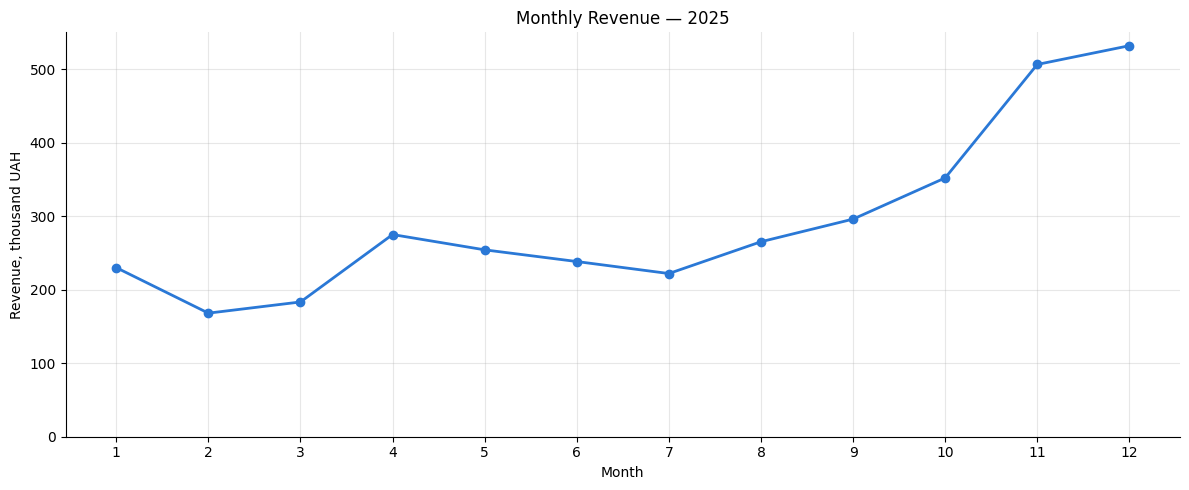

In [15]:
# Побудова лінійного графіка виручки
plt.figure(figsize=(12, 5))

plt.plot(
    monthly.index,
    monthly["Revenue"] / 1000,
    marker="o"
)

plt.title("Monthly Revenue — 2025")
plt.xlabel("Month")
plt.ylabel("Revenue, thousand UAH")

plt.xticks(range(1, 13))
plt.ylim(bottom=0)

plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [16]:
# Визначення найкращого та найслабшого місяців
best_month = monthly["Revenue"].idxmax()
worst_month = monthly["Revenue"].idxmin()

print("Найкращий місяць:", best_month)
print("Найслабший місяць:", worst_month)

print("Виручка найкращого місяця:",
      monthly.loc[best_month, "Revenue"])

print("Виручка найслабшого місяця:",
      monthly.loc[worst_month, "Revenue"])


Найкращий місяць: 12
Найслабший місяць: 2
Виручка найкращого місяця: 532250
Виручка найслабшого місяця: 168220


In [17]:
# Різниця між найкращим і найслабшим місяцями у відсотках

difference = (
    (monthly["Revenue"].max() - monthly["Revenue"].min())
    / monthly["Revenue"].min() * 100
)

print(f"Різниця між найкращим і найслабшим місяцями: {difference:.2f}%")

Різниця між найкращим і найслабшим місяцями: 216.40%


---
## Крок 5. Товари та категорії

**Завдання:**
1. Знайдіть топ-5 товарів за **виручкою** і топ-5 за **прибутком**. Чи збігаються списки?
2. Створіть таблицю **`categories`**: виручка, прибуток і маржа (`margin_%` = прибуток / виручка × 100) по категоріях.
3. 📈 Побудуйте горизонтальний графік прибутку по категоріях: найбільша зверху, з підписами значень.

In [18]:
product_sales = delivered.groupby(
    ["product_id", "product"]
).agg(
    Revenue=("revenue", "sum"),
    Profit=("profit", "sum")
)

# Топ-5 за виручкою
top_revenue = product_sales.sort_values(
    "Revenue", ascending=False
).head(5)

# Топ-5 за прибутком
top_profit = product_sales.sort_values(
    "Profit", ascending=False
).head(5)

print("ТОП-5 товарів за виручкою:")
display(top_revenue)

print("ТОП-5 товарів за прибутком:")
display(top_profit)

ТОП-5 товарів за виручкою:


,,Revenue,Profit
product_id,product,,
P03,Smartwatch,483000,149500
P15,Perfume,326400,149600
P04,Bluetooth speaker,277200,105600
P08,Sneakers,252000,108000
P06,Hoodie,243600,131950


ТОП-5 товарів за прибутком:


,,Revenue,Profit
product_id,product,,
P15,Perfume,326400,149600
P03,Smartwatch,483000,149500
P06,Hoodie,243600,131950
P08,Sneakers,252000,108000
P04,Bluetooth speaker,277200,105600


In [19]:
# Чи збігаються списки топ-5?
same_products = set(top_revenue.index) & set(top_profit.index)

print("Кількість товарів, які є в обох ТОП-5:", len(same_products))
print("Спільні товари:")

for product in same_products:
    print(product)

Кількість товарів, які є в обох ТОП-5: 5
Спільні товари:
('P06', 'Hoodie')
('P08', 'Sneakers')
('P03', 'Smartwatch')
('P04', 'Bluetooth speaker')
('P15', 'Perfume')


In [20]:
# Створення таблиці categories
categories = delivered.groupby("category").agg(
    Revenue=("revenue", "sum"),
    Profit=("profit", "sum")
)

categories["margin_%"] = (
    categories["Profit"] / categories["Revenue"] * 100
)

display(categories.sort_values("Profit", ascending=False))

,Revenue,Profit,margin_%
category,,,
Electronics,1143600,412680,36.09
Clothing,812700,409570,50.40
Home,594480,312020,52.49
Beauty,544540,277870,51.03
Sports,429500,214560,49.96


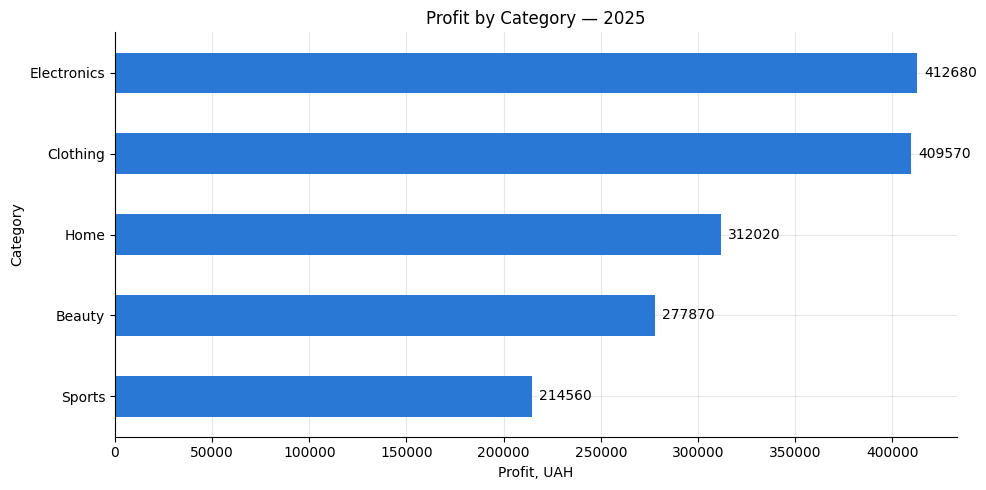

In [21]:
# Горизонтальний графік прибутку по категоріях
profit_by_category = categories["Profit"].sort_values(
    ascending=True
)

plt.figure(figsize=(10, 5))

ax = profit_by_category.plot(
    kind="barh",
    color="#2a78d6"
)

ax.bar_label(
    ax.containers[0],
    fmt="%.0f",
    padding=5
)

plt.title("Profit by Category — 2025")
plt.xlabel("Profit, UAH")
plt.ylabel("Category")
plt.xlim(left=0)

plt.tight_layout()
plt.show()

In [22]:
# Чи збігаються суми категорій із річними KPI.
print("Revenue:", categories["Revenue"].sum())
print("Profit:", categories["Profit"].sum())

print("Revenue check:",
      np.isclose(categories["Revenue"].sum(), kpi["Revenue"]))

print("Profit check:",
      np.isclose(categories["Profit"].sum(), kpi["Profit"]))

Revenue: 3524820
Profit: 1626700
Revenue check: True
Profit check: True


---
## Крок 6. Міста і канали продажів

**Завдання:**
Побудуйте зведену таблицю **`city_channel`**: рядки — міста, стовпці — канали продажів, у клітинках — виручка (по доставлених), з рядком і стовпцем «Всього». Яке місто і який канал дають найбільше?

In [23]:
# Створення зведеної таблиці city_channel
city_channel = pd.pivot_table(
    delivered,
    index="city",
    columns="channel",
    values="revenue",
    aggfunc="sum",
    fill_value=0,
    margins=True,
    margins_name="Всього"
)

display(city_channel)

channel,App,Instagram,Website,Всього
city,,,,
Dnipro,172750,79490,228510,480750
Kharkiv,202170,106270,255520,563960
Kyiv,364070,169220,599060,1132350
Lviv,252670,157160,377660,787490
Odesa,214740,65830,279700,560270
Всього,1206400,577970,1740450,3524820


In [24]:
# Пошук міста з найбільшою виручкою
best_city = city_channel["Всього"].drop("Всього").idxmax()

best_city_revenue = city_channel.loc[best_city, "Всього"]

print("Найкраще місто:", best_city)
print("Виручка:", best_city_revenue)

Найкраще місто: Kyiv
Виручка: 1132350


In [26]:
# Пошук найкращого каналу продажів
best_channel = city_channel.loc["Всього"].drop("Всього").idxmax()

best_channel_revenue = city_channel.loc["Всього", best_channel]

print("Найкращий канал:", best_channel)
print("Виручка:", best_channel_revenue)

Найкращий канал: Website
Виручка: 1740450


In [28]:
# Найкраща комбінація міста та каналу
city_channel_only = city_channel.drop("Всього").drop(
    columns="Всього"
)

best_combination = city_channel_only.stack().idxmax()

print("Найкраща комбінація:", best_combination)
print("Виручка:", city_channel_only.stack().max())

Найкраща комбінація: ('Kyiv', 'Website')
Виручка: 599060


In [30]:
# Перевірка загальної суми
print(
    "Revenue check:",
    city_channel.loc["Всього", "Всього"] == kpi["Revenue"]
)

Revenue check: True


---
## Крок 7. Клієнти

**Завдання:**
1. Порахуйте для кожного покупця кількість доставлених замовлень і їхню загальну суму. Назвіть таблицю **`buyers`**.
2. Яка частка покупців купила **більше одного разу** (повторні покупці)?
3. Складіть **`top10`** — 10 клієнтів з найбільшою сумою покупок, з іменем і містом.
4. ⭐ Розбийте покупців на вікові групи (18–24, 25–34, 35–44, 45+) і порахуйте виручку кожної групи.

In [31]:
# Створення таблиці buyers
buyers = delivered.groupby("customer_id").agg(
    Orders=("order_id", "count"),
    Revenue=("revenue", "sum")
)

# Додаємо інформацію про клієнтів
buyers = buyers.merge(
    customers[["customer_id", "name", "city", "age"]],
    on="customer_id",
    how="left"
)

display(buyers.head())

,customer_id,Orders,Revenue,name,city,age
0,C0001,3,3500,Sofiia,Lviv,29
1,C0002,10,11870,Tetiana,Dnipro,27
2,C0003,8,5590,Andrii,Kharkiv,35
3,C0004,4,1930,Iryna,Dnipro,29
4,C0005,3,3110,Sofiia,Odesa,40


In [32]:
# Частка повторних покупців
repeat_buyers = (buyers["Orders"] > 1).sum()

repeat_share = repeat_buyers / len(buyers) * 100

print("Повторні покупці:", repeat_buyers)
print("Усього покупців:", len(buyers))
print(f"Частка повторних покупців: {repeat_share:.2f}%")

Повторні покупці: 301
Усього покупців: 353
Частка повторних покупців: 85.27%


In [33]:
# Створення top10 — найцінніші клієнти
top10 = buyers.sort_values(
    "Revenue",
    ascending=False
).head(10)

display(
    top10[["name", "city", "Orders", "Revenue"]]
)

,name,city,Orders,Revenue
218,Olena,Lviv,37,56090
164,Oleksandr,Kyiv,37,50830
309,Ihor,Kyiv,27,45440
82,Ihor,Kyiv,28,41800
41,Mariia,Kharkiv,22,40830
193,Taras,Kyiv,22,39250
239,Ihor,Kharkiv,29,38780
138,Dmytro,Lviv,23,37940
152,Serhii,Lviv,27,35000
304,Oksana,Dnipro,20,34970


In [38]:
# Аналіз покупців за віковими групами
buyers["age_group"] = pd.cut(
    buyers["age"],
    bins=[18, 25, 35, 45, 66],
    labels=["18-24", "25-34", "35-44", "45+"],
    right=False
)

# Тепер порахуємо виручку кожної вікової групи:

age_revenue = buyers.groupby(
    "age_group",
    observed=False
)["Revenue"].sum()

display(age_revenue)

,Revenue
age_group,
18-24,648980
25-34,1559120
35-44,1023470
45+,293250


In [39]:
# Чи збігається сума покупок усіх клієнтів із річною виручкою
print(
    "Revenue check:",
    np.isclose(buyers["Revenue"].sum(), kpi["Revenue"])
)

Revenue check: True


In [40]:
# Чи всі 353 покупці отримали інформацію про вік:
print("Пропуски у віці:", buyers["age"].isna().sum())

Пропуски у віці: 0


---
## Крок 8. Де проблеми?

**Завдання:**
1. Яка частка скасованих і повернених замовлень для кожного **способу оплати** (по **всіх** замовленнях `data`)?
2. Як середня оцінка залежить від **часу доставки** (`delivery_days`)?
3. Який середній час доставки в кожному місті?

Які проблеми ви бачите і що можна порадити бізнесу?

In [41]:
# Скасування та повернення за способом оплати
payment_issues = pd.crosstab(
    data["payment"],
    data["status"],
    normalize="index"
) * 100

display(payment_issues.round(2))

status,Cancelled,Delivered,Returned
payment,,,
Card,5.57,91.20,3.23
Cash on delivery,11.41,81.12,7.48
Google/Apple Pay,4.07,92.61,3.33


In [42]:
# Як оцінка залежить від часу доставки?
delivery_rating = data.groupby(
    "delivery_days"
).agg(
    Average_Rating=("rating", "mean"),
    Orders=("order_id", "count")
)

display(delivery_rating.round(2))

,Average_Rating,Orders
delivery_days,,
1.00,4.08,835
2.00,4.06,824
3.00,4.03,394
4.00,3.44,383
5.00,3.46,359


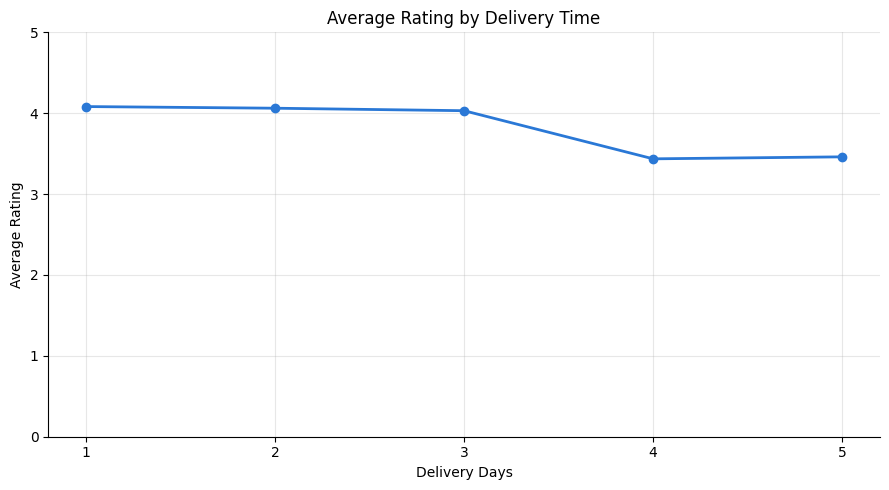

In [43]:
# Побудова графіка
plt.figure(figsize=(9, 5))

plt.plot(
    delivery_rating.index,
    delivery_rating["Average_Rating"],
    marker="o"
)

plt.title("Average Rating by Delivery Time")
plt.xlabel("Delivery Days")
plt.ylabel("Average Rating")
plt.xticks(range(1, 6))
plt.ylim(0, 5)
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

In [44]:
# Середній час доставки в кожному місті
city_delivery = data.groupby("city").agg(
    Average_Delivery_Days=("delivery_days", "mean"),
    Orders=("delivery_days", "count")
).sort_values(
    "Average_Delivery_Days",
    ascending=False
)

display(city_delivery.round(2))

,Average_Delivery_Days,Orders
city,,
Dnipro,3.05,406
Lviv,3.03,633
Odesa,3.00,405
Kharkiv,2.82,450
Kyiv,1.50,901


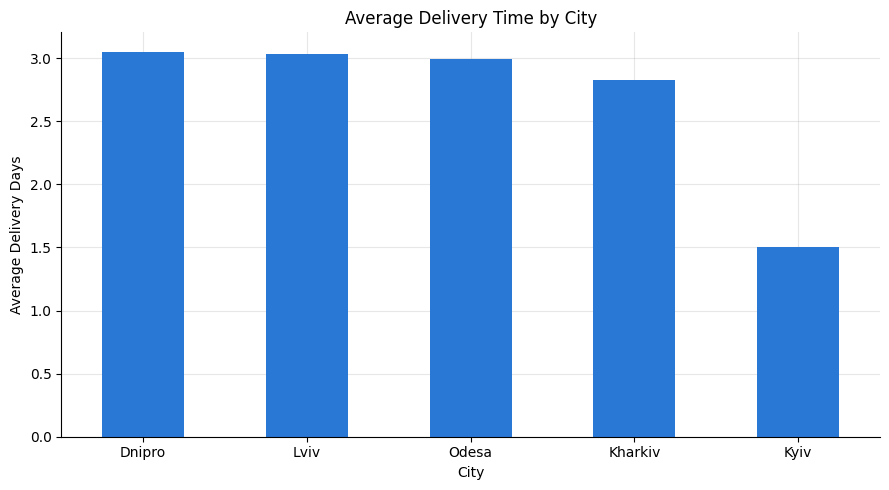

In [45]:
# Графік доставки за містами
plt.figure(figsize=(9, 5))

city_delivery["Average_Delivery_Days"].plot(
    kind="bar",
    color="#2a78d6"
)

plt.title("Average Delivery Time by City")
plt.xlabel("City")
plt.ylabel("Average Delivery Days")
plt.xticks(rotation=0)
plt.ylim(bottom=0)

plt.tight_layout()
plt.show()

In [46]:
# Найпроблемніші показники

# Спосіб оплати з найбільшою часткою скасувань
worst_cancel_payment = payment_issues["Cancelled"].idxmax()

# Спосіб оплати з найбільшою часткою повернень
worst_return_payment = payment_issues["Returned"].idxmax()

# Місто з найдовшою доставкою
slowest_city = city_delivery["Average_Delivery_Days"].idxmax()

print("Найбільше скасувань:", worst_cancel_payment)
print("Найбільше повернень:", worst_return_payment)
print("Найповільніша доставка:", slowest_city)

Найбільше скасувань: Cash on delivery
Найбільше повернень: Cash on delivery
Найповільніша доставка: Dnipro


---
## 📈 Крок 9. Дашборд на одній картинці

Керівник не читатиме десять таблиць. Зберіть **чотири головні графіки** на одній картинці (сітка 2 × 2), щоб усю історію року було видно за 10 секунд:

| Місце | Що показує | Питання |
|---|---|---|
| ліворуч угорі | виручка по місяцях | як ішли продажі? |
| праворуч угорі | прибуток по категоріях | що заробляє гроші? |
| ліворуч унизу | частка скасованих замовлень за способом оплати | де втрачаємо? |
| праворуч унизу | середня оцінка залежно від днів доставки | що дратує клієнтів? |

**Завдання:**
1. Побудуйте дашборд зі спільним заголовком.
2. Виділіть кольором те, на що керівник має звернути увагу (найгірший спосіб оплати, довгу доставку), а решту залиште нейтральною.
3. Збережіть дашборд у файл **`dashboard_2025.png`**.

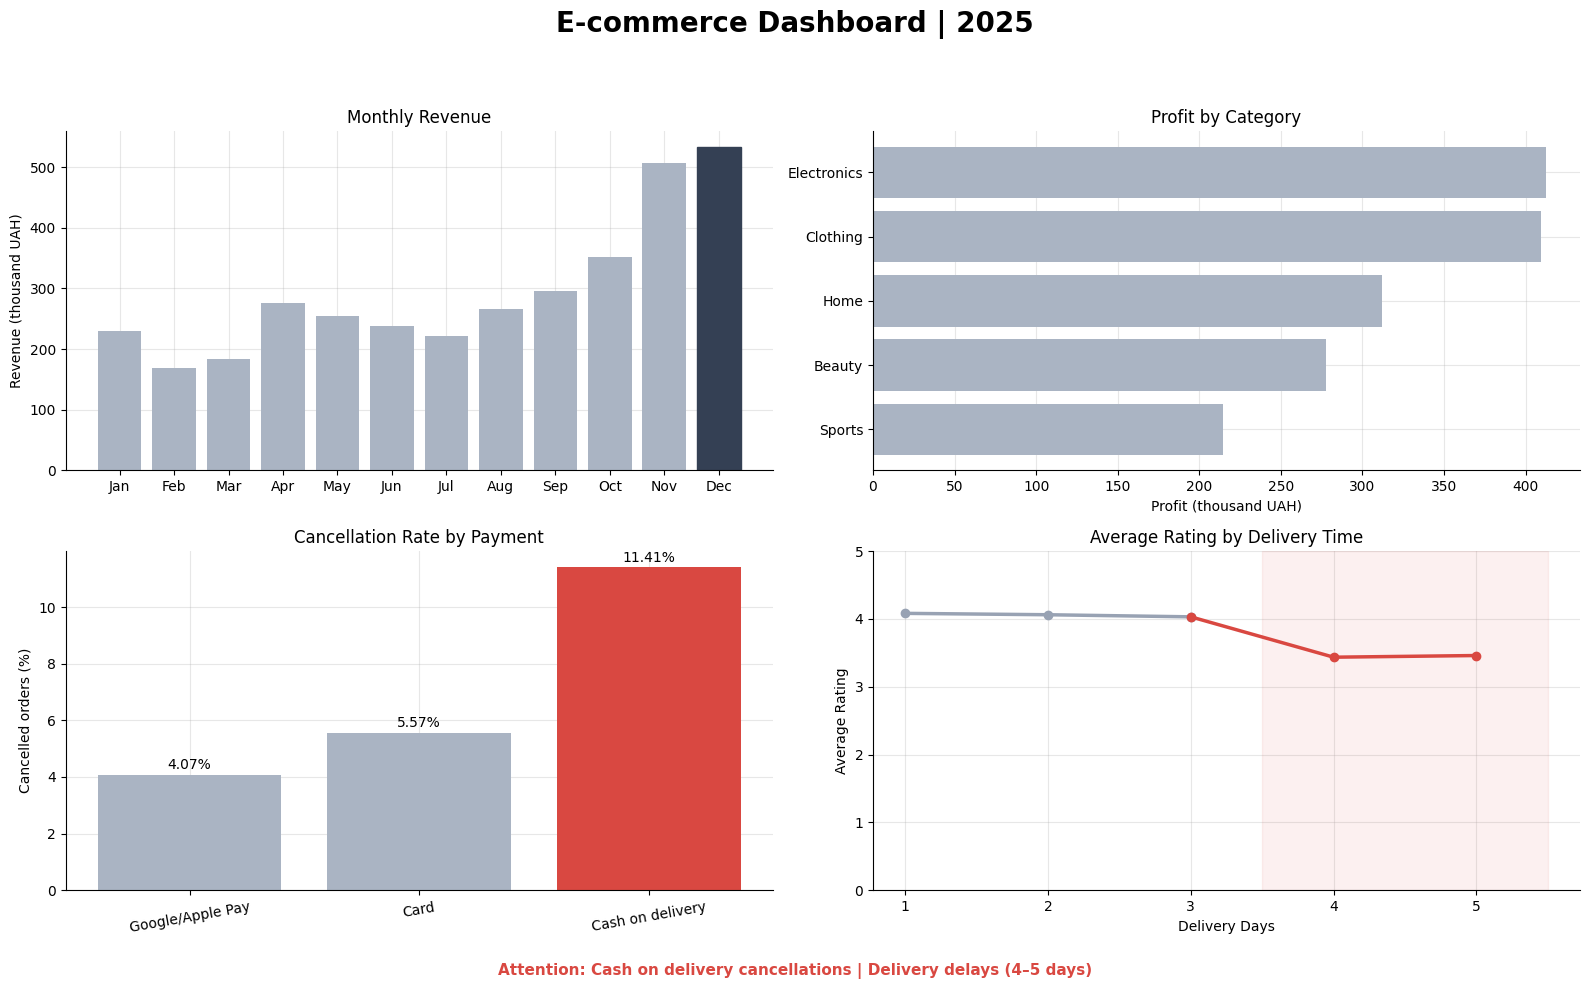

In [47]:
import matplotlib.pyplot as plt
import numpy as np

# Створюємо полотно з 4 графіками
fig, axes = plt.subplots(2, 2, figsize=(16, 10))

fig.suptitle(
    "E-commerce Dashboard | 2025",
    fontsize=20,
    fontweight="bold"
)

# 1. Виручка по місяцях
monthly_revenue = delivered.groupby(
    delivered["order_date"].dt.month
)["revenue"].sum()

monthly_revenue = monthly_revenue.reindex(range(1, 13), fill_value=0)

months = ["Jan", "Feb", "Mar", "Apr", "May", "Jun",
          "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]

axes[0, 0].bar(
    months,
    monthly_revenue.values / 1000,
    color="#AAB4C3"
)

axes[0, 0].set_title("Monthly Revenue")
axes[0, 0].set_ylabel("Revenue (thousand UAH)")
axes[0, 0].grid(axis="y", alpha=0.3)
axes[0, 0].set_axisbelow(True)

# Виділяємо найкращий місяць
best_month = monthly_revenue.idxmax()
axes[0, 0].patches[best_month - 1].set_color("#344054")


# 2. Прибуток по категоріях
category_profit = delivered.groupby("category")["profit"].sum()
category_profit = category_profit.sort_values()

axes[0, 1].barh(
    category_profit.index,
    category_profit.values / 1000,
    color="#AAB4C3"
)

axes[0, 1].set_title("Profit by Category")
axes[0, 1].set_xlabel("Profit (thousand UAH)")
axes[0, 1].grid(axis="x", alpha=0.3)
axes[0, 1].set_axisbelow(True)


# 3. Частка скасованих замовлень за оплатою
payment_cancel = (
    data.assign(cancelled=(data["status"] == "Cancelled"))
    .groupby("payment")["cancelled"]
    .mean() * 100
)

payment_cancel = payment_cancel.sort_values()

colors = [
    "#D94841" if payment == payment_cancel.idxmax()
    else "#AAB4C3"
    for payment in payment_cancel.index
]

bars = axes[1, 0].bar(
    payment_cancel.index,
    payment_cancel.values,
    color=colors
)

axes[1, 0].set_title("Cancellation Rate by Payment")
axes[1, 0].set_ylabel("Cancelled orders (%)")
axes[1, 0].tick_params(axis="x", rotation=10)
axes[1, 0].grid(axis="y", alpha=0.3)
axes[1, 0].set_axisbelow(True)

for bar, value in zip(bars, payment_cancel.values):
    axes[1, 0].text(
        bar.get_x() + bar.get_width() / 2,
        value + 0.2,
        f"{value:.2f}%",
        ha="center"
    )


# 4. Середня оцінка залежно від днів доставки
delivery_rating = data.groupby("delivery_days").agg(
    Average_Rating=("rating", "mean")
)

delivery_rating = delivery_rating.dropna()

days = delivery_rating.index
ratings = delivery_rating["Average_Rating"]

axes[1, 1].plot(
    days[days <= 3],
    ratings[days <= 3],
    marker="o",
    linewidth=2.5,
    color="#98A2B3"
)

axes[1, 1].plot(
    days[days >= 3],
    ratings[days >= 3],
    marker="o",
    linewidth=2.5,
    color="#D94841"
)

axes[1, 1].axvspan(3.5, 5.5, color="#D94841", alpha=0.08)

axes[1, 1].set_title("Average Rating by Delivery Time")
axes[1, 1].set_xlabel("Delivery Days")
axes[1, 1].set_ylabel("Average Rating")
axes[1, 1].set_ylim(0, 5)
axes[1, 1].set_xticks(sorted(days))
axes[1, 1].grid(alpha=0.3)


# Загальне оформлення
plt.tight_layout(rect=[0, 0.04, 1, 0.94])

fig.text(
    0.5, 0.015,
    "Attention: Cash on delivery cancellations | Delivery delays (4–5 days)",
    ha="center",
    color="#D94841",
    fontsize=11,
    fontweight="bold"
)

# Збереження у файл
plt.savefig(
    "dashboard_2025.png",
    dpi=180,
    bbox_inches="tight"
)

plt.show()

---
## Крок 10. Звіт в Excel

**Завдання:**
1. Збережіть таблиці в **один файл** `report_2025.xlsx` з аркушами: KPI, Місяці, Категорії, Міста і канали, Топ-10 клієнтів.
2. 📈 Додайте аркуш «Дашборд» і вставте на нього картинку з кроку 9.
3. Перевірте результат: прочитайте файл назад і переконайтеся, що всі аркуші на місці.

In [48]:
import pandas as pd
import os
from openpyxl import load_workbook
from openpyxl.drawing.image import Image
from openpyxl.styles import Font, PatternFill, Alignment
from openpyxl.utils import get_column_letter

# Назва фінального файлу
file_name = "report_2025.xlsx"

# Перевіряємо, чи існує картинка з Кроку 9
dashboard_path = "dashboard_2025.png"

if not os.path.exists(dashboard_path):
    raise FileNotFoundError(
        "Не знайдено dashboard_2025.png. "
        "Спочатку виконай Крок 9."
    )

# 1. Готуємо таблиці для Excel
kpi_df = kpi.rename("Value").rename_axis("Metric").reset_index()

monthly_df = monthly.reset_index()
categories_df = categories.reset_index()
city_channel_df = city_channel.reset_index()
top10_df = top10.reset_index()

# 2. Записуємо всі таблиці в один Excel-файл
with pd.ExcelWriter(file_name, engine="openpyxl") as writer:

    kpi_df.to_excel(
        writer, sheet_name="KPI", index=False
    )

    monthly_df.to_excel(
        writer, sheet_name="Місяці", index=False
    )

    categories_df.to_excel(
        writer, sheet_name="Категорії", index=False
    )

    city_channel_df.to_excel(
        writer, sheet_name="Міста і канали", index=False
    )

    top10_df.to_excel(
        writer, sheet_name="Топ-10 клієнтів", index=False
    )

# 3. Відкриваємо файл і створюємо аркуш Дашборд
wb = load_workbook(file_name)

ws = wb.create_sheet("Дашборд")

# Додаємо заголовок
ws["A1"] = "E-commerce Dashboard | 2025"
ws["A1"].font = Font(
    bold=True,
    size=18,
    color="FFFFFF"
)
ws["A1"].fill = PatternFill(
    "solid",
    fgColor="344054"
)
ws.merge_cells("A1:N1")

# Вставляємо картинку з Кроку 9
img = Image(dashboard_path)

# Задаємо розмір зображення
img.width = 1200
img.height = 760

ws.add_image(img, "A3")

# Налаштовуємо ширину колонок
for col in range(1, 15):
    ws.column_dimensions[get_column_letter(col)].width = 14

# 4. Оформлюємо таблиці
for sheet in wb.worksheets:
    if sheet.title == "Дашборд":
        continue

    # Закріплюємо заголовок
    sheet.freeze_panes = "A2"

    # Стиль заголовків
    for cell in sheet[1]:
        cell.font = Font(bold=True, color="FFFFFF")
        cell.fill = PatternFill("solid", fgColor="344054")
        cell.alignment = Alignment(horizontal="center")

    # Автоматична ширина колонок
    for column in sheet.columns:
        max_length = max(
            len(str(cell.value)) if cell.value is not None else 0
            for cell in column
        )
        column_letter = get_column_letter(column[0].column)
        sheet.column_dimensions[column_letter].width = min(
            max_length + 3, 35
        )

# 5. Зберігаємо Excel-файл
wb.save(file_name)

print(f"Файл успішно збережено: {file_name}")

Файл успішно збережено: report_2025.xlsx


In [49]:
# Перевірка результату
# Повторно читаємо створений Excel-файл
check = pd.ExcelFile("report_2025.xlsx")

print("Аркуші у файлі:")
for sheet in check.sheet_names:
    print("-", sheet)

# Перевіряємо, чи є всі 6 потрібних аркушів
expected_sheets = [
    "KPI",
    "Місяці",
    "Категорії",
    "Міста і канали",
    "Топ-10 клієнтів",
    "Дашборд"
]

assert set(expected_sheets).issubset(set(check.sheet_names))

# Перевіряємо наявність картинки на аркуші Дашборд
wb_check = load_workbook("report_2025.xlsx")
assert len(wb_check["Дашборд"]._images) == 1

print("\nПеревірка успішна!")
print("Усі аркуші на місці, дашборд додано.")

Аркуші у файлі:
- KPI
- Місяці
- Категорії
- Міста і канали
- Топ-10 клієнтів
- Дашборд

Перевірка успішна!
Усі аркуші на місці, дашборд додано.


---
## Крок 11. Висновки для керівника

Цифри самі по собі нічого не означають, поки аналітик не перетворить їх на **висновки й рекомендації**. Це найважливіша частина роботи.

**Завдання:** напишіть 4–5 коротких висновків. Кожен висновок — це **факт з цифрою** і **рекомендація**.

**Мої висновки** (двічі клацніть, щоб редагувати):

1. …
2. …
3. …
4. …

Мої висновки:  1. **Продажі зростають наприкінці року.** Найбільша виручка була у грудні — **532 250 грн**, а найменша в лютому — **168 220 грн**. Рекомендація: планувати збільшення запасів товарів, рекламних бюджетів і персоналу перед піковим сезоном листопада–грудня.

2. **Електроніка приносить найбільший прибуток, але має низьку маржинальність.** Прибуток категорії становить **412 680 грн**, а маржа — лише **36,09%**. Рекомендація: переглянути закупівельні ціни, умови постачання та цінову політику цієї категорії.

3. **Післяплата пов'язана з найбільшою кількістю проблемних замовлень.** Для Cash on delivery частка скасувань становить **11,41%**, а повернень — **7,48%**. Рекомендація: запровадити підтвердження замовлень і стимули для клієнтів обирати передоплату.

4. **Тривала доставка негативно пов'язана із задоволеністю клієнтів.** При доставці за 1–3 дні середня оцінка становить приблизно **4,0 бала**, а за 4–5 днів знижується до **3,44–3,46 бала**. Рекомендація: скоротити терміни доставки та контролювати замовлення, що затримуються понад 3 дні.

5. **Київ має найшвидшу доставку серед досліджених міст.** Середній термін становить **1,50 дня**, тоді як у Дніпрі — **3,05 дня**. Рекомендація: проаналізувати логістичні маршрути Дніпра та інших міст і використати досвід доставки в Києві для оптимізації процесів.

---
# 📈 Шпаргалка: який графік обрати

| Питання | Графік | Як у pandas |
|---|---|---|
| Як змінювалося з часом? | лінійний | `s.plot()` |
| Хто більше, хто менше? | горизонтальні стовпчики, відсортовані | `s.sort_values().plot(kind="barh")` |
| Порівняти кілька показників у групах | згруповані стовпчики | `pivot.plot(kind="bar")` |
| З чого складається ціле? | складені або 100%-ві стовпчики | `pivot.plot(kind="barh", stacked=True)` |
| Як розподілені значення? | гістограма | `s.plot(kind="hist", bins=20)` |
| Чи є зв'язок між двома числами? | точкова діаграма | `df.plot(kind="scatter", x=..., y=...)` |
| Багато категорій у динаміці | малі мультиплікатори | `pivot.plot(subplots=True, layout=(2, 3), sharey=True)` |
| Потрібні точні числа | теплова таблиця | `table.style.background_gradient()` |

### ⚠️ Типові помилки
1. **Немає заголовка або одиниць виміру.** Читач не знає, що це: гривні, штуки чи відсотки.
2. **Стовпчики не від нуля.** Невелика різниця виглядає як прірва. Для стовпчиків вісь завжди починається з 0.
3. **Невідсортовані категорії.** Читачеві доводиться самому шукати найбільше.
4. **Кругова діаграма з багатьма секторами.** Кути око порівнює погано, а 5+ секторів не порівнює взагалі. Краще горизонтальні стовпчики.
5. **Дві осі Y на одному графіку.** Майже завжди заплутують. Краще два графіки поруч (`plt.subplots`).
6. **Забагато кольорів.** Колір має значення: виділяйте ним головне, решту робіть сірою.
7. **Заголовок без висновку.** «Продажі по місяцях» гірше, ніж «Продажі зросли вдвічі за осінь».